In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv(r"C:\Users\sumeh\OneDrive\Desktop\BTT-AIF26\Healthcare-2B-predicting-heart-disease-risk-from-health-survey-indicators\data\heart_2022_no_nans.csv")
print("shape: ", df.shape)
print(df.columns.tolist())
print(df.dtypes, "\n")
print(df.head(), "\n")



shape:  (246022, 40)
['State', 'Sex', 'GeneralHealth', 'PhysicalHealthDays', 'MentalHealthDays', 'LastCheckupTime', 'PhysicalActivities', 'SleepHours', 'RemovedTeeth', 'HadHeartAttack', 'HadAngina', 'HadStroke', 'HadAsthma', 'HadSkinCancer', 'HadCOPD', 'HadDepressiveDisorder', 'HadKidneyDisease', 'HadArthritis', 'HadDiabetes', 'DeafOrHardOfHearing', 'BlindOrVisionDifficulty', 'DifficultyConcentrating', 'DifficultyWalking', 'DifficultyDressingBathing', 'DifficultyErrands', 'SmokerStatus', 'ECigaretteUsage', 'ChestScan', 'RaceEthnicityCategory', 'AgeCategory', 'HeightInMeters', 'WeightInKilograms', 'BMI', 'AlcoholDrinkers', 'HIVTesting', 'FluVaxLast12', 'PneumoVaxEver', 'TetanusLast10Tdap', 'HighRiskLastYear', 'CovidPos']
State                            str
Sex                              str
GeneralHealth                    str
PhysicalHealthDays           float64
MentalHealthDays             float64
LastCheckupTime                  str
PhysicalActivities               str
SleepHours 

In [2]:
df = df.replace(["", " ", "NA", "N/A", "null", "None", "?", "-"], np.nan)
 
missing_count = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)
 
missing_report = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_pct
})
missing_report = missing_report[missing_report["missing_count"] > 0]
missing_report = missing_report.sort_values("missing_count", ascending=False)
 
print("=== Missing values per column ===")
print(missing_report if not missing_report.empty else "No missing values found.")

rows_with_missing = df[df.isnull().any(axis=1)]
print(f"\nRows with at least one missing value: {len(rows_with_missing)}")

=== Missing values per column ===
No missing values found.

Rows with at least one missing value: 0


## Discovering Skeweness in numerical columns

## We calculated the amount of values for each numerical columns and looked at IQR values and Z-score outliers. After analyzing our results, we noticed that PhysicalHealthDays and MentalHealthDays may be skewed (i.e PhysicalHealthDays has 38,810 observation outside of IQR bounds), but we did not know by which direction
## Thus, for more specific data, we calculuated the skeweness for each columns using .skew()
## We observed that 4 of our 5 columns were skewed towards the right

**PhysicalHealthDays** is heavily skewed towards the right (skew = 2.284305) with most respondents at 0 days and some clusters at 5 and 30 days. The mean (~4.12) is being pulled upward relative to the median (0.00) by this tail.
**MentalHealthDays** is heavily skewed towards the right (skew = 2.215269) with most respondents at 0 days and some clusters at 5 and 30 days. The mean (~4.17) is being pulled upward relative to the median (0.00) by this tail.
**SleepHours** is roughly symmetric with skew = 0.561437
**HeightInMeters** is also roughly symmetric with skew = 0.031681
**WeightInKilograms** is skewed towards the right (skew = 1.024990) with most respondents at around 50-100 kilograms. 
**BMI** is skewed towards the right (skew = 1.326496) with most respondents reporting a BMI of around 20-30

For logistic regression we'll consider a log transform or binning; tree-based models can use the raw values as is.


=== Outlier summary ===
            column  iqr_lower  iqr_upper  iqr_outliers  zscore_outliers
PhysicalHealthDays     -4.500      7.500         38810            17160
  MentalHealthDays     -6.000     10.000         32714            13963
        SleepHours      3.000     11.000          3488             3488
    HeightInMeters      1.405      2.005           830              530
 WeightInKilograms     27.225    136.065          5940             2385
               BMI     12.840     43.320          7563             3091

=== Skewness of key numeric columns ===
PhysicalHealthDays    2.284305
MentalHealthDays      2.215269
SleepHours            0.561437
HeightInMeters        0.031681
WeightInKilograms     1.024990
BMI                   1.326496
dtype: float64

=== Graphs of key numeric columns ===


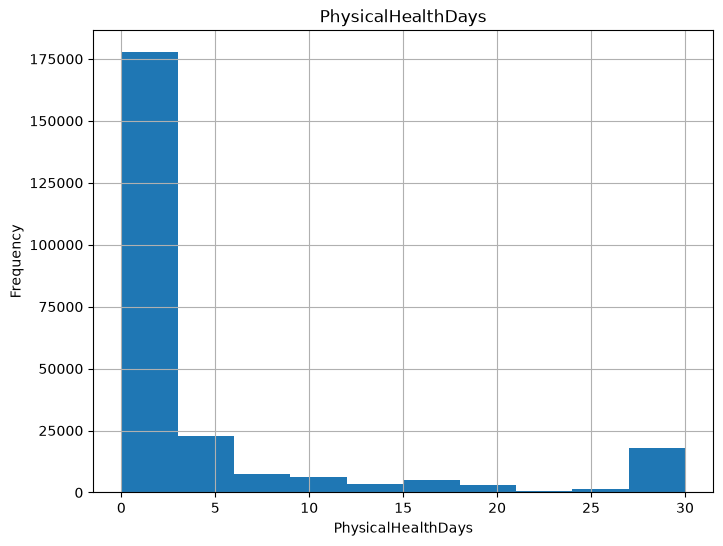

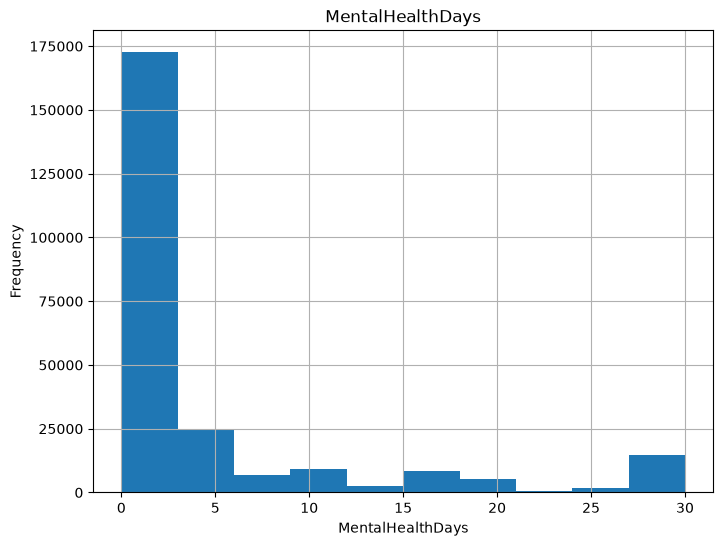

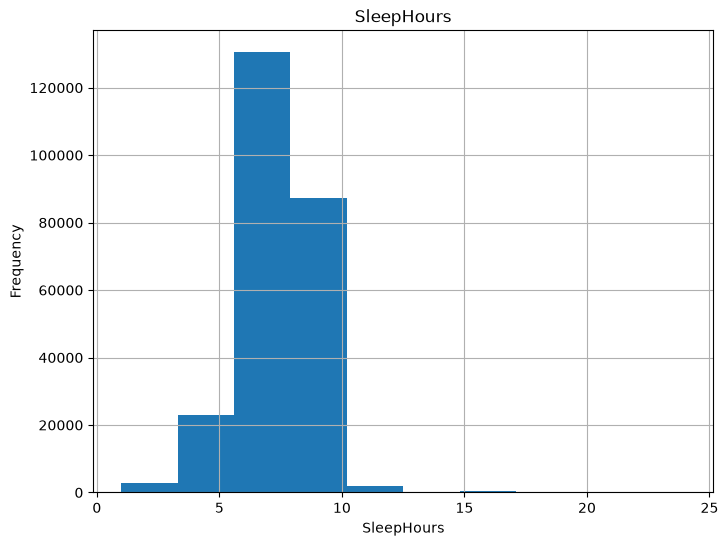

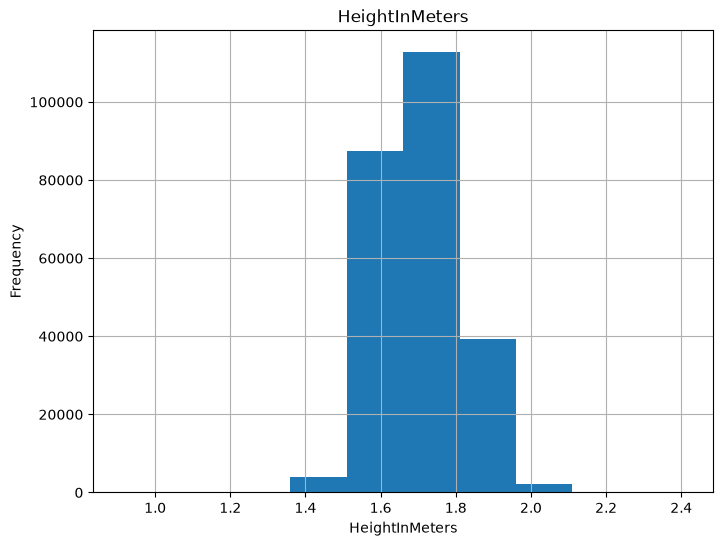

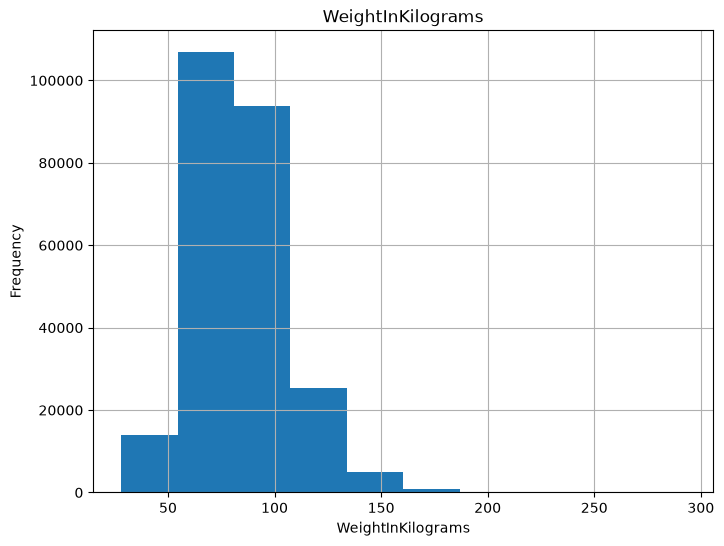

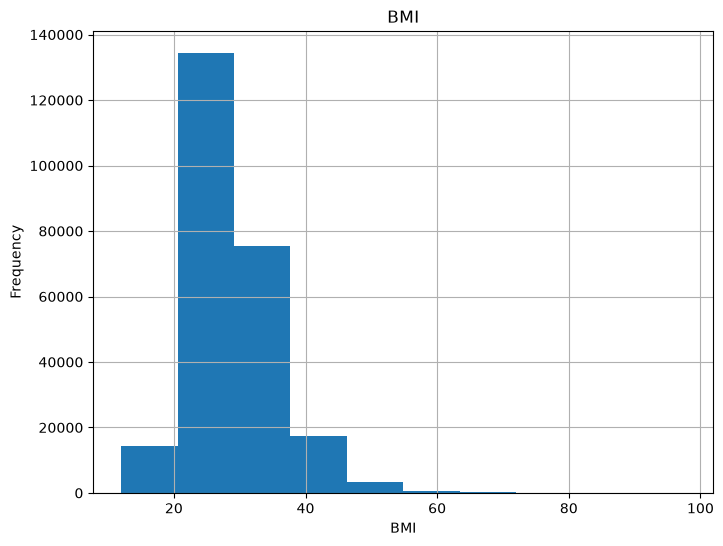


=== Record mean and median values ===
Mean values:
PhysicalHealthDays     4.119026
MentalHealthDays       4.167140
SleepHours             7.021331
HeightInMeters         1.705150
WeightInKilograms     83.615179
BMI                   28.668136
dtype: float64
Median values:
PhysicalHealthDays     0.00
MentalHealthDays       0.00
SleepHours             7.00
HeightInMeters         1.70
WeightInKilograms     81.65
BMI                   27.46
dtype: float64


In [3]:
numeric_cols = df.select_dtypes(include="number").columns
 
 
def iqr_outliers(series, k=1.5):
    """Flag values outside [Q1 - k*IQR, Q3 + k*IQR]."""
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - k * iqr, q3 + k * iqr
    return (series < lower) | (series > upper), lower, upper
 
 
def zscore_outliers(series, threshold=3):
    """Flag values more than `threshold` standard deviations from the mean."""
    s = series.dropna()
    z = (s - s.mean()) / s.std()
    return z.abs() > threshold
 
 
outlier_summary = []
outlier_rows = {}
 
for col in numeric_cols:
    series = df[col].dropna()
 
    # Method A: IQR
    mask_iqr, lower, upper = iqr_outliers(series)
    # Method B: Z-score
    mask_z = zscore_outliers(series)
 
    outlier_summary.append({
        "column": col,
        "iqr_lower": round(lower, 3),
        "iqr_upper": round(upper, 3),
        "iqr_outliers": int(mask_iqr.sum()),
        "zscore_outliers": int(mask_z.sum()),
    })
    outlier_rows[col] = df.loc[mask_iqr[mask_iqr].index, col]
 
print("\n=== Outlier summary ===")
print(pd.DataFrame(outlier_summary).to_string(index=False))

print("\n=== Skewness of key numeric columns ===")
print(df[["PhysicalHealthDays", "MentalHealthDays", "SleepHours", "HeightInMeters", "WeightInKilograms", "BMI"]].skew())

print("\n=== Graphs of key numeric columns ===")
import matplotlib.pyplot as plt

for col in ["PhysicalHealthDays", "MentalHealthDays", "SleepHours", "HeightInMeters", "WeightInKilograms", "BMI"]:
    plt.figure(figsize=(8, 6))
    df[col].hist()
    plt.title(col)
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

print("\n=== Record mean and median values ===")

print("Mean values:")
print(df[["PhysicalHealthDays", "MentalHealthDays", "SleepHours", "HeightInMeters", "WeightInKilograms", "BMI"]].mean())

print("Median values:")
print(df[["PhysicalHealthDays", "MentalHealthDays", "SleepHours", "HeightInMeters", "WeightInKilograms", "BMI"]].median())
      


## Categorical Columns
## Using .value_counts, we identified which columns had rare categories. State was the only column with rare state categories. Noting that state has over 40 categories (making it tedious to encode) and assuming that is make be weak in predicitng heart disease/heart attack (compared to other potential features), we decided to exclude it

In [4]:
# Identify rare categories in categorical columns
categorical_cols = df.select_dtypes(include="object").columns
for col in categorical_cols:
    counts = df[col].value_counts(normalize=True)
    rare = counts[counts < 0.01]
    if not rare.empty:
        print(f"--- {col} ---")
        print(rare)
        print()

--- State ---
State
Mississippi             0.009910
Kentucky                0.009808
Wyoming                 0.009796
Delaware                0.008759
Alabama                 0.007731
Nevada                  0.007190
District of Columbia    0.007012
Guam                    0.006296
Virgin Islands          0.003020
Name: proportion, dtype: float64



C:\Users\sumeh\AppData\Local\Temp\ipykernel_7192\3642211676.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns


--- HadDiabetes ---
HadDiabetes
Yes, but only during pregnancy (female)    0.00806
Name: proportion, dtype: float64



## Splitting data into training and test sets

In [5]:
# Splitting data into training and testing sets
from sklearn.model_selection import train_test_split
X = df.drop(columns=["HadHeartAttack"]) 
y = df["HadHeartAttack"].map({"Yes": 1, "No": 0})
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
threshold = 0.01
threshold = 0.01
train_counts = X_train["State"].value_counts(normalize=True)
rare_categories = train_counts[train_counts < threshold].index

X_train["State"] = X_train["State"].replace(rare_categories, "Other")
X_test["State"] = X_test["State"].replace(rare_categories, "Other")
print(y_train.mean(), y_test.mean())


0.05460910388838362 0.05460827151712224


## Finding correlations

In [6]:
from scipy.stats import chi2_contingency

#sample_idx = X_train.sample(n=15000, random_state=42).index
#X_sample = X_train.loc[sample_idx]
#y_sample = y_train.loc[sample_idx]

def calc_cramersv(df, feature, target):
    contingency_table = pd.crosstab(df[feature], target)
    chi2, p_value, _, _= chi2_contingency(contingency_table)
    n = contingency_table.sum().sum()
    min_dim = min(contingency_table.shape) - 1

    if min_dim == 0:
        return 0.0, 1.0
    cramers_v = np.sqrt(chi2 / (n * min_dim))
    return cramers_v, p_value

results = []
for col in X_train.select_dtypes(include="object").columns:
    v_score, p_val = calc_cramersv(X_train, col, y_train)
    results.append({
        'Feature': col,
        'Cramer_V (Strength)': round(v_score, 4),
        'P-Value (Significance)': round(p_val, 4),
        'Is_Significant': p_val < 0.05  # Standard threshold
    })
correlation_df = pd.DataFrame(results).sort_values(by='Cramer_V (Strength)', ascending=False)
print(correlation_df)

C:\Users\sumeh\AppData\Local\Temp\ipykernel_7192\3075879866.py:19: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in X_train.select_dtypes(include="object").columns:


                      Feature  Cramer_V (Strength)  P-Value (Significance)  \
6                   HadAngina               0.4472                     0.0   
2               GeneralHealth               0.2002                     0.0   
25                AgeCategory               0.1797                     0.0   
7                   HadStroke               0.1792                     0.0   
5                RemovedTeeth               0.1705                     0.0   
23                  ChestScan               0.1662                     0.0   
18          DifficultyWalking               0.1594                     0.0   
14                HadDiabetes               0.1488                     0.0   
10                    HadCOPD               0.1338                     0.0   
29              PneumoVaxEver               0.1204                     0.0   
13               HadArthritis               0.1165                     0.0   
12           HadKidneyDisease               0.1092              

Cramers V values were generally low (0.04-0.44). This indicates that no single categorical variable strongly predicts HadHeartAttack in strong isolation. We are retaining most categorical features at this stage and will use ensemble modeling to help determine final feature set. 

## Feature Engineering

In [7]:
"""Encoding"""
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

X_train = X_train.drop(columns=["WeightInKilograms", "HeightInMeters"])
X_test = X_test.drop(columns=["WeightInKilograms", "HeightInMeters"])
# Categorical 
health_order = {"Poor": 0, "Fair": 1, "Good": 2, "Very good": 3, "Excellent": 4}
smoker_order = {"Never smoked": 0, "Former smoker": 1, "Current smoker - now smokes some days": 2, "Current smoker - now smokes every day": 3}
diabetes = {"No": 1, "No, pre-diabetes or borderline diabetes": 2, "Yes, but only during pregnancy (female)": 3, "Yes": 4}
X_train["HadDiabetes"] = X_train["HadDiabetes"].map(diabetes)
X_test["HadDiabetes"] = X_test["HadDiabetes"].map(diabetes)
X_train["GeneralHealth"] = X_train["GeneralHealth"].map(health_order)
X_test["GeneralHealth"] = X_test["GeneralHealth"].map(health_order)
yes_no_cols = ["PhysicalActivities", "AlcoholDrinkers", "HIVTesting", "FluVaxLast12", "PneumoVaxEver", "HighRiskLastYear", "CovidPos",
               "HadAngina", "HadStroke", "HadAsthma", "HadSkinCancer", "HadDepressiveDisorder", "HadKidneyDisease", "HadArthritis", "DeafOrHardOfHearing",
               "BlindOrVisionDifficulty", "DifficultyConcentrating", "DifficultyWalking", "DifficultyDressingBathing", "DifficultyErrands", "ChestScan"]
X_train["SmokerStatus"] = X_train["SmokerStatus"].map(smoker_order)
X_test["SmokerStatus"] = X_test["SmokerStatus"].map(smoker_order)

for col in yes_no_cols:
    print(col, X_train[col].unique())
    X_train[col] = X_train[col].map({"Yes": 1, "Tested positive using home test without a health professional": 1, "No": 0})
    X_test[col] = X_test[col].map({"Yes": 1, "Tested positive using home test without a health professional": 1, "No": 0})
    n_new_na = X_train[col].isna().sum()
    if n_new_na > 0:
        print(f"  WARNING: {n_new_na} NaNs introduced in {col} — check unmapped categories")

#One-hot encode State column
encoder = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)

encoded_train = encoder.fit_transform(X_train[["State"]])
encoded_test = encoder.transform(X_test[["State"]])

encoded_train_df = pd.DataFrame(
    encoded_train,
    columns=encoder.get_feature_names_out(["State"]),
    index=X_train.index
)
encoded_test_df = pd.DataFrame(
    encoded_test,
    columns=encoder.get_feature_names_out(["State"]),
    index=X_test.index
)
X_train = pd.concat([X_train.drop(columns=["State"]), encoded_train_df], axis=1)
X_test = pd.concat([X_test.drop(columns=["State"]), encoded_test_df], axis=1)

#Log transformation
skewed_cols = ["BMI", "PhysicalHealthDays", "MentalHealthDays"]
for col in skewed_cols:
    X_train[col] = np.log1p(X_train[col])
    X_test[col] = np.log1p(X_test[col])
# Numerical
scaler = StandardScaler()
numeric_cols = ["BMI", "SleepHours", "PhysicalHealthDays", "MentalHealthDays"]  
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

PhysicalActivities <StringArray>
['No', 'Yes']
Length: 2, dtype: str
AlcoholDrinkers <StringArray>
['No', 'Yes']
Length: 2, dtype: str
HIVTesting <StringArray>
['No', 'Yes']
Length: 2, dtype: str
FluVaxLast12 <StringArray>
['Yes', 'No']
Length: 2, dtype: str
PneumoVaxEver <StringArray>
['Yes', 'No']
Length: 2, dtype: str
HighRiskLastYear <StringArray>
['No', 'Yes']
Length: 2, dtype: str
CovidPos <StringArray>
['No', 'Yes', 'Tested positive using home test without a health professional']
Length: 3, dtype: str
HadAngina <StringArray>
['Yes', 'No']
Length: 2, dtype: str
HadStroke <StringArray>
['No', 'Yes']
Length: 2, dtype: str
HadAsthma <StringArray>
['No', 'Yes']
Length: 2, dtype: str
HadSkinCancer <StringArray>
['Yes', 'No']
Length: 2, dtype: str
HadDepressiveDisorder <StringArray>
['No', 'Yes']
Length: 2, dtype: str
HadKidneyDisease <StringArray>
['No', 'Yes']
Length: 2, dtype: str
HadArthritis <StringArray>
['No', 'Yes']
Length: 2, dtype: str
DeafOrHardOfHearing <StringArray>
['No',

In [9]:
#Tests
X_train.isna().sum()[X_train.isna().sum() > 0]
X_test.isna().sum()[X_test.isna().sum() > 0]
print(X_train.shape, X_test.shape)
assert list(X_train.columns) == list(X_test.columns)


(196817, 81) (49205, 81)
